# 03 · FBCCA 滤波器组典型相关分析

FBCCA（Filter Bank CCA, Chen et al., 2015）是 CCA 的增强版，也是**无训练数据时
的主力方法**。本笔记：

1. 理解为什么要做"滤波器组"：把基频与各次谐波**分频段**利用；
2. 掌握子带设计与经典融合权重；
3. 观察各子带的相关系数，对比 CCA 与 FBCCA 在不同噪声下的鲁棒性。

In [1]:
# 导入数值计算、绘图和工程模块，并设置 notebook 的显示参数

from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd().parent))  # 让 notebook 能 import 上级目录的 ssvep 包
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.unicode_minus': False})
np.set_printoptions(precision=3, suppress=True)
print('环境就绪，工程路径已加入 sys.path')

环境就绪，工程路径已加入 sys.path


## 一、动机：谐波信息要"分频段"利用

标准 CCA 的参考信号虽然包含谐波，但所有频率成分混在一次相关计算里，
高频谐波（2f、3f…）能量较弱，容易被基频和噪声主导。

FBCCA 的做法：

1. 先用一组**带通滤波器组**把 EEG 分解到多个子带，第 $n$ 个子带主要覆盖
   第 $n$ 次谐波附近；
2. 每个子带信号分别与参考信号做 CCA，得到 $\rho_n$；
3. 按经验权重把各子带相关系数的**平方**加权求和：

$$\hat{\rho}_k = \sum_{n=1}^{N} w_n\, \rho_{n,k}^2,
\qquad w_n = n^{-1.25} + 0.25$$

经典子带设置为第 $n$ 带通带 $[8n,\,90]$ Hz（$n=1,\ldots,5$）。

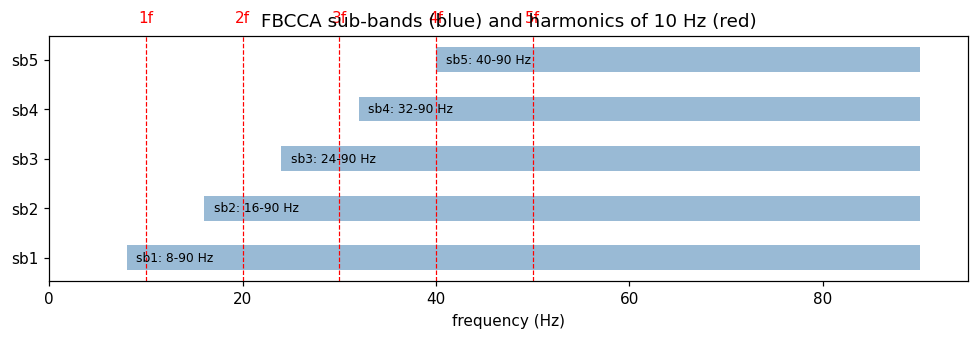

In [2]:
# 绘制 FBCCA 子带范围及 10 Hz 刺激的谐波位置示意图

# 子带频带示意：以 10Hz 刺激为例，红线为 f~5f 的谐波位置
# 第 n 个子带从 8n Hz 起、到 90 Hz 止；随着 n 增大逐步抑制较低频率。
# 这样能分别观察基频附近和较高阶谐波的信息。
bands = [(8.0*n, 90.0) for n in range(1, 6)]
fig, ax = plt.subplots(figsize=(9, 3.2))
# 蓝色横条表示每个子带的通带范围；红线是 10 Hz 刺激的各阶谐波。
for n, (lo, hi) in enumerate(bands):
    ax.barh(n, hi-lo, left=lo, height=0.5, color='steelblue', alpha=0.55)
    ax.text(lo+1, n, f'sb{n+1}: {lo:.0f}-{hi:.0f} Hz', va='center', fontsize=8)
for h in range(1, 6):
    # h=1..5 对应基频 10 Hz 到第五次谐波 50 Hz。
    ax.axvline(10*h, color='red', ls='--', lw=0.8)
    ax.text(10*h, 4.75, f'{h}f', color='red', ha='center')
ax.set(xlim=(0, 95), xlabel='frequency (Hz)', yticks=range(5),
       yticklabels=[f'sb{i+1}' for i in range(5)],
       title='FBCCA sub-bands (blue) and harmonics of 10 Hz (red)')
plt.tight_layout(); plt.show()

In [3]:
# 生成带有多类别标签的模拟 SSVEP 训练与测试数据

def make_ssvep(n_classes=8, n_ch=9, fs=250, duration=3.0, n_trials=8,
               noise=0.6, seed=0):
    '''生成模拟 SSVEP 数据：基频+2/3 次谐波经固定空间混合，加高斯噪声。
    返回 trials(n_trials*n_classes, n_ch, T), labels, freqs。'''
    rng = np.random.default_rng(seed)
    freqs = np.arange(8.0, 8.0 + n_classes)
    T = int(fs * duration)
    t = np.arange(T) / fs
    mixing = rng.normal(size=(n_ch, 3))          # 谐波源 -> 通道 的空间混合
    phases = rng.uniform(0, 2*np.pi, size=(n_classes, 3))
    X, y = [], []
    for k, f in enumerate(freqs):
        src = np.vstack([np.sin(2*np.pi*h*f*t + phases[k, h-1]) for h in (1, 2, 3)])
        clean = mixing @ src
        for _ in range(n_trials):
            X.append(clean + noise*rng.normal(size=(n_ch, T)))
            y.append(k)
    return np.array(X), np.array(y), freqs

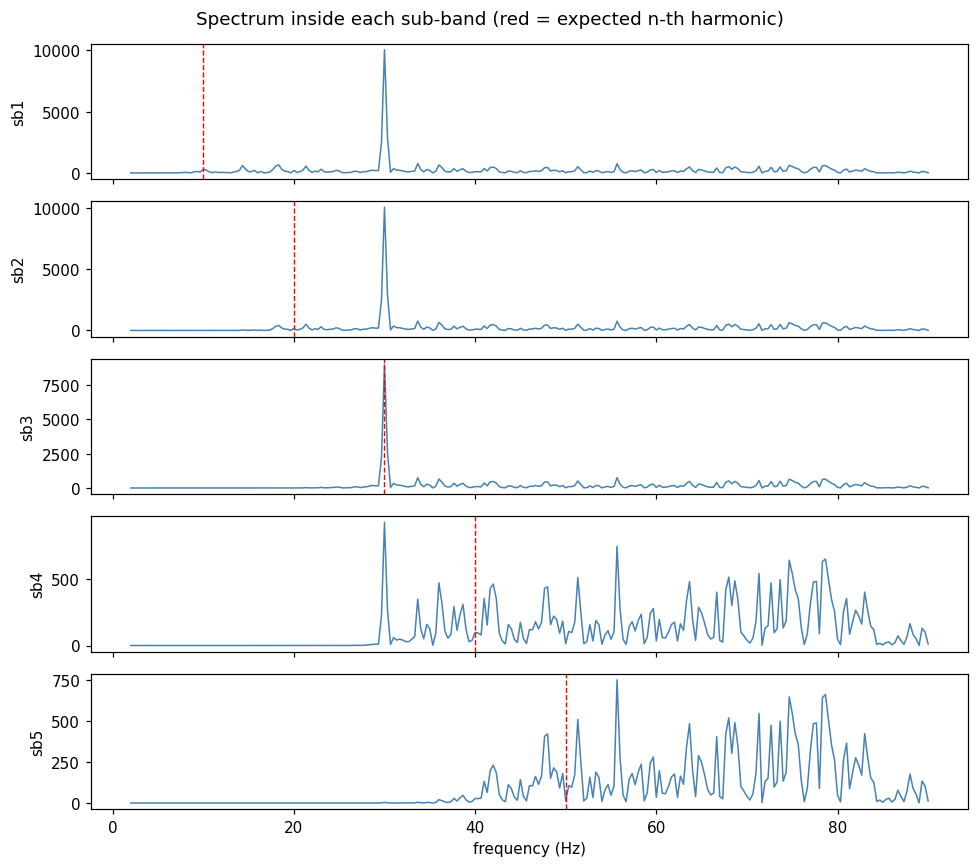

In [4]:
# 将一个 SSVEP 试次分解到多个子带，观察各子带的频谱响应

# 观察一个 10Hz 片段经过各子带后的频谱：子带 n 中第 n 次谐波最突出
from ssvep.preprocess import filterbank
trials, labels, freqs = make_ssvep(noise=0.8)
seg = trials[labels == 2][0]   # 类 2 对应 10 Hz，与示意图一致
# 每个子带单独滤波，便于观察基频及不同阶谐波在各频段的能量。
# subs 是子带信号列表；每个元素形状仍为 (通道数, 时间点数)。
subs = filterbank(seg, 250, bands)

def spectrum(x, fs):
    # 对单个通道去均值并加 Hann 窗，降低有限长度截断产生的频谱泄漏。
    x = x - x.mean(); n = len(x)
    sp = np.abs(np.fft.rfft(x*np.hanning(n)))**2
    return np.fft.rfftfreq(n, 1/fs), sp

fig, axes = plt.subplots(len(subs), 1, figsize=(9, 8), sharex=True)
# 每个子带画一张频谱；红线标出该子带预期重点保留的谐波频率。
for nb, xb in enumerate(subs):
    fr, sp = spectrum(xb[0], 250); m = (fr >= 2) & (fr <= 90)
    axes[nb].plot(fr[m], sp[m], color='steelblue', lw=1)
    axes[nb].axvline(10*(nb+1), color='red', ls='--', lw=0.9)
    axes[nb].set_ylabel(f'sb{nb+1}')
axes[-1].set_xlabel('frequency (Hz)')
fig.suptitle('Spectrum inside each sub-band (red = expected n-th harmonic)')
plt.tight_layout(); plt.show()

## 二、各子带的典型相关系数

对每个子带分别计算"正确频率 10 Hz"和"错误频率 12 Hz"的 CCA 相关系数。
正确频率在多个子带上都占优，加权后区分度被放大。

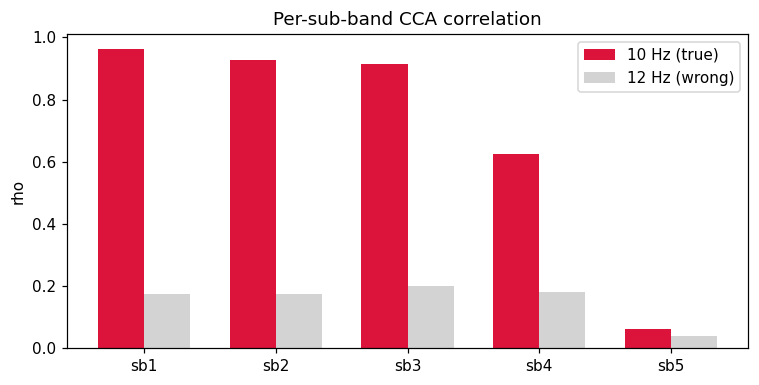

融合权重 w_n = [1.25  0.67  0.503 0.427 0.384]
正确频率加权得分 = 2.322
错误频率加权得分 = 0.094


In [5]:
# 比较各子带对正确与错误频率的 CCA 得分，并计算加权融合结果

from ssvep.cca import cca_max_corr
from ssvep.reference import reference_signal
T = seg.shape[-1]
rho_true, rho_wrong = [], []
for xb in subs:
    rho_true.append(cca_max_corr(xb, reference_signal(10, 250, T, 3))[0])
    rho_wrong.append(cca_max_corr(xb, reference_signal(12, 250, T, 3))[0])
x = np.arange(len(subs)); w = 0.35
plt.figure(figsize=(7, 3.6))
plt.bar(x-w/2, rho_true, w, label='10 Hz (true)', color='crimson')
plt.bar(x+w/2, rho_wrong, w, label='12 Hz (wrong)', color='lightgray')
plt.xticks(x, [f'sb{i+1}' for i in x]); plt.ylabel('rho'); plt.legend()
plt.title('Per-sub-band CCA correlation')
plt.tight_layout(); plt.show()

ns = np.arange(1, len(subs)+1)
wn = ns**(-1.25) + 0.25
print('融合权重 w_n =', np.round(wn, 3))
print('正确频率加权得分 = %.3f' % np.sum(wn*np.array(rho_true)**2))
print('错误频率加权得分 = %.3f' % np.sum(wn*np.array(rho_wrong)**2))

## 三、整体分类：CCA vs FBCCA

`ssvep/cca.py` 的 `FBCCAClassifier` 实现了上述流程（内部自动滤波器组 + 加权）。
在不同噪声强度下对比（3 个随机种子平均）。

> **关于模拟数据的诚实说明**：本笔记的模拟信号是"纯谐波源经线性混合 + 白噪声"，
> 恰好完全符合 CCA 的信号模型，因此 CCA 在这种数据上已接近理论最优，FBCCA 的
> 增益不明显（短窗口下子带滤波的边缘效应甚至会让它略低）。**FBCCA 相对 CCA 的
> 稳定优势体现在真实 SSVEP 数据上**——真实信号存在谐波畸变、有色背景噪声、
> 个体差异，且刺激频率更密集（清华 Benchmark 40 个目标间隔仅 0.2 Hz）。
> 请用 `examples/run_benchmark.py` 在真实公开数据上验证这一结论。

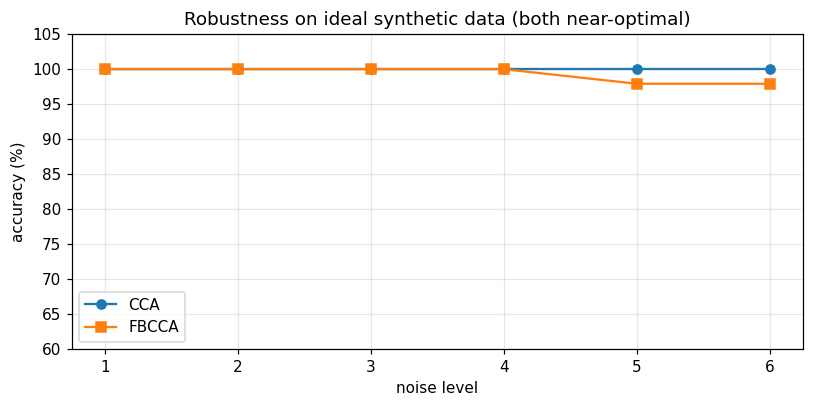

noise: [1, 2, 3, 4, 5, 6]
CCA  : [100. 100. 100. 100. 100. 100.]
FBCCA: [100.  100.  100.  100.   97.9  97.9]


In [6]:
# 在不同噪声强度下比较标准 CCA 与 FBCCA 的分类准确率

from ssvep import CCAClassifier, FBCCAClassifier
noise_levels = [1, 2, 3, 4, 5, 6]
acc_cca, acc_fb = [], []
for nz in noise_levels:
    a1, a2 = [], []
    for seed in range(3):
        # 每个噪声强度重复 3 个随机种子，降低一次随机模拟带来的偶然性。
        X, y, fr = make_ssvep(noise=nz, seed=seed)
        a1.append((CCAClassifier(fr, 250, n_harmonics=3).predict_batch(X) == y).mean()*100)
        a2.append((FBCCAClassifier(fr, 250, n_harmonics=3).predict_batch(X) == y).mean()*100)
    acc_cca.append(np.mean(a1)); acc_fb.append(np.mean(a2))
plt.figure(figsize=(7.5, 3.8))
plt.plot(noise_levels, acc_cca, 'o-', label='CCA')
plt.plot(noise_levels, acc_fb, 's-', label='FBCCA')
plt.xlabel('noise level'); plt.ylabel('accuracy (%)'); plt.legend()
plt.ylim(60, 105)
plt.title('Robustness on ideal synthetic data (both near-optimal)')
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print('noise:', noise_levels)
print('CCA  :', np.round(acc_cca, 1))
print('FBCCA:', np.round(acc_fb, 1))

## 小结与调参建议

- FBCCA = **滤波器组 + 每子带 CCA + 权重融合**，把谐波信息分频段利用；
  在真实 SSVEP 数据（谐波畸变、频率密集、有色噪声）上通常比单带 CCA 更稳。
- 关键可调参数：子带个数（默认 5）、子带边界（$[8n,90]$）、谐波数 $N_h$、权重指数。
- 仍然**不需要训练数据**，计算量与 CCA 同量级，是比赛中"先提交一版"的推荐主力。
- 若能拿到带标签的被试训练数据，下一笔记的 **TRCA** 通常还能再提一截准确率。